# Used Car Price Prediction Using Artificial Neural Network (ANN)

## 1. Data Exploration

### Project Overview
This project aims to develop a machine learning model to predict the prices of used cars in the Indian market. The project will explore vehicle attributes, prepare the dataset, and evaluate an Artificial Neural Network (ANN) against a baseline regression model.

### Objective
The objective of this notebook is to understand the dataset's structure, identify data-quality issues, analyze the target variable, and explore relationships between vehicle characteristics and used-car prices.

### Dataset Description
- **Dataset file:** `car_details.csv`
- **Source location:** `data/raw/`
- **Target variable:** `Price` (used-car price in Indian Rupees)
- **Initial dataset size:** 2,059 rows and 20 columns

### Exploration Scope
1. Load and inspect the dataset.
2. Review the target variable and descriptive statistics.
3. Analyze price distributions and relationships with selected vehicle characteristics.
4. Identify missing values, duplicate records, and categorical-value distributions.
5. Summarize the findings to inform data preprocessing.


## 2. Library Imports

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

## 3. Load the Dataset

In [10]:
DATA_PATH = Path("../data/raw/car_details.csv")

df = pd.read_csv(DATA_PATH)
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (2059, 20)


,Make,Model,Price,Year,Kilometer,Fuel Type,Transmission,Location,Color,Owner,Seller Type,Engine,Max Power,Max Torque,Drivetrain,Length,Width,Height,Seating Capacity,Fuel Tank Capacity
0,Honda,Amaze 1.2 VX i-VTEC,505000,2017,87150,Petrol,Manual,Pune,Grey,First,Corporate,1198 cc,87 bhp @ 6000 rpm,109 Nm @ 4500 rpm,FWD,3990.0,1680.0,1505.0,5.0,35.0
1,Maruti Suzuki,Swift DZire VDI,450000,2014,75000,Diesel,Manual,Ludhiana,White,Second,Individual,1248 cc,74 bhp @ 4000 rpm,190 Nm @ 2000 rpm,FWD,3995.0,1695.0,1555.0,5.0,42.0
2,Hyundai,i10 Magna 1.2 Kappa2,220000,2011,67000,Petrol,Manual,Lucknow,Maroon,First,Individual,1197 cc,79 bhp @ 6000 rpm,112.7619 Nm @ 4000 rpm,FWD,3585.0,1595.0,1550.0,5.0,35.0
3,Toyota,Glanza G,799000,2019,37500,Petrol,Manual,Mangalore,Red,First,Individual,1197 cc,82 bhp @ 6000 rpm,113 Nm @ 4200 rpm,FWD,3995.0,1745.0,1510.0,5.0,37.0
4,Toyota,Innova 2.4 VX 7 STR [2016-2020],1950000,2018,69000,Diesel,Manual,Mumbai,Grey,First,Individual,2393 cc,148 bhp @ 3400 rpm,343 Nm @ 1400 rpm,RWD,4735.0,1830.0,1795.0,7.0,55.0


## 4. Target Variable Analysis

In [11]:
print("Target column: Price")

print("\nPrice summary:")
print(df["Price"].describe())

print("\nMissing prices:", df["Price"].isnull().sum())

print("\nMinimum price: ₹", df["Price"].min())
print("Maximum price: ₹", df["Price"].max())
print("Median price: ₹", df["Price"].median())

Target column: Price

Price summary:
count    2.059000e+03
mean     1.702992e+06
std      2.419881e+06
min      4.900000e+04
25%      4.849990e+05
50%      8.250000e+05
75%      1.925000e+06
max      3.500000e+07
Name: Price, dtype: float64

Missing prices: 0

Minimum price: ₹ 49000
Maximum price: ₹ 35000000
Median price: ₹ 825000.0


## 5. Price Distribution

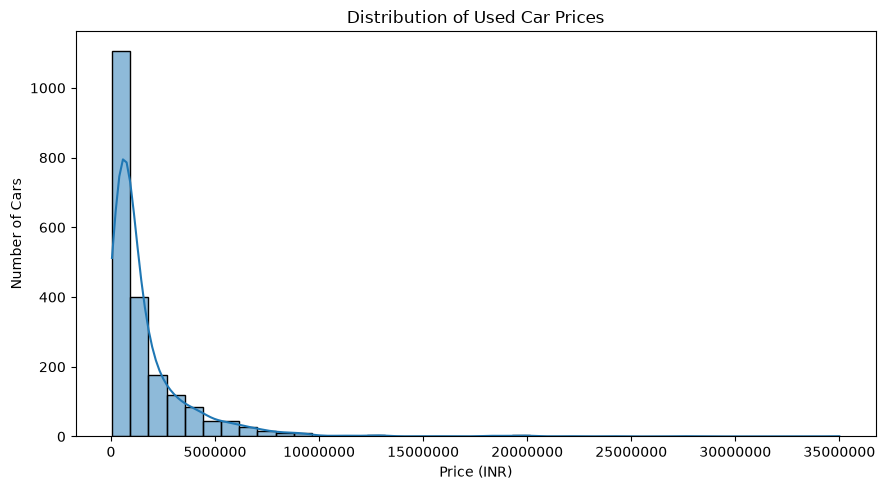

In [12]:
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x="Price", bins=40, kde=True)

plt.title("Distribution of Used Car Prices")
plt.xlabel("Price (INR)")
plt.ylabel("Number of Cars")
plt.ticklabel_format(style="plain", axis="x")

plt.tight_layout()
plt.show()

## 6. Feature Relationships

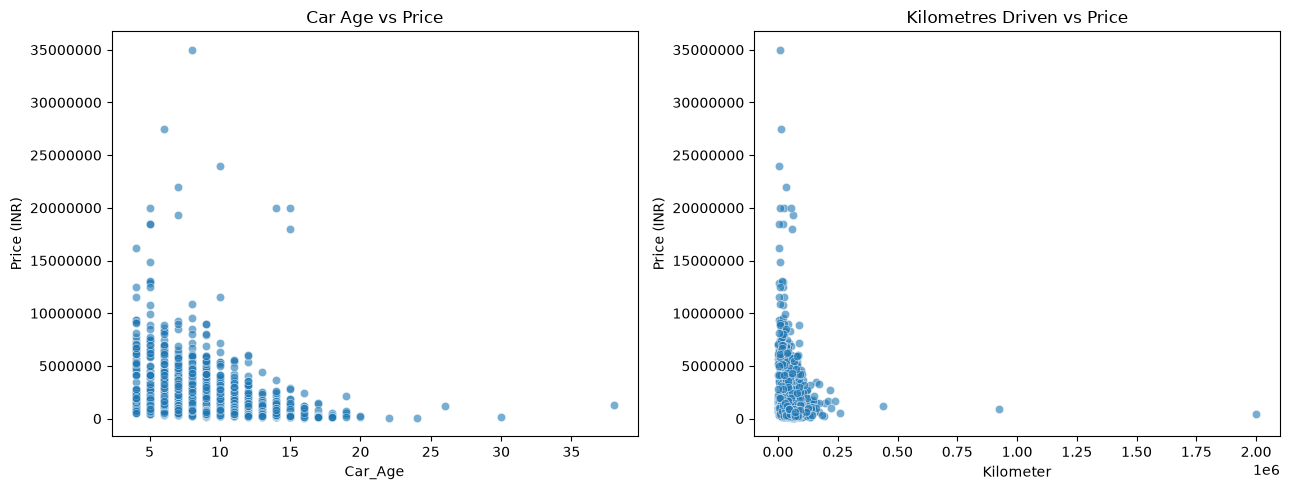

In [13]:
current_year = pd.Timestamp.now().year

df["Car_Age"] = current_year - df["Year"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(
    data=df,
    x="Car_Age",
    y="Price",
    alpha=0.6,
    ax=axes[0]
)
axes[0].set_title("Car Age vs Price")
axes[0].set_ylabel("Price (INR)")
axes[0].ticklabel_format(style="plain", axis="y")

sns.scatterplot(
    data=df,
    x="Kilometer",
    y="Price",
    alpha=0.6,
    ax=axes[1]
)
axes[1].set_title("Kilometres Driven vs Price")
axes[1].set_ylabel("Price (INR)")
axes[1].ticklabel_format(style="plain", axis="y")

plt.tight_layout()
plt.show()

## 7. Data Quality Assessment

In [14]:
# Check column names
print("Columns in the dataset:")
print(df.columns.tolist())

# Check data types
print("\nData types:")
print(df.dtypes)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Columns in the dataset:
['Make', 'Model', 'Price', 'Year', 'Kilometer', 'Fuel Type', 'Transmission', 'Location', 'Color', 'Owner', 'Seller Type', 'Engine', 'Max Power', 'Max Torque', 'Drivetrain', 'Length', 'Width', 'Height', 'Seating Capacity', 'Fuel Tank Capacity', 'Car_Age']

Data types:
Make                      str
Model                     str
Price                   int64
Year                    int64
Kilometer               int64
Fuel Type                 str
Transmission              str
Location                  str
Color                     str
Owner                     str
Seller Type               str
Engine                    str
Max Power                 str
Max Torque                str
Drivetrain                str
Length                float64
Width                 float64
Height                float64
Seating Capacity      float64
Fuel Tank Capacity    float64
Car_Age                 int64
dtype: object

Missing values:
Engine                 80
Max Power            

## 8. Duplicate Records and Categorical Features

In [15]:
# Check for duplicate records
print("Duplicate rows:", df.duplicated().sum())

# Check unique values in categorical columns
categorical_columns = [
    "Make", "Model", "Fuel Type", "Transmission",
    "Location", "Owner", "Seller Type", "Drivetrain"
]

for column in categorical_columns:
    print(f"\n{column}: {df[column].nunique()} unique values")
    print(df[column].value_counts().head(5))

Duplicate rows: 0

Make: 33 unique values
Make
Maruti Suzuki    440
Hyundai          349
Mercedes-Benz    171
Honda            158
Toyota           132
Name: count, dtype: int64

Model: 1050 unique values
Model
X1 sDrive20d xLine                 15
Swift DZire VDI                    14
Fortuner 2.8 4x2 AT [2016-2020]    13
City V                             13
Swift DZire VXI                    12
Name: count, dtype: int64

Fuel Type: 9 unique values
Fuel Type
Diesel      1049
Petrol       942
CNG           50
Electric       7
LPG            5
Name: count, dtype: int64

Transmission: 2 unique values
Transmission
Manual       1133
Automatic     926
Name: count, dtype: int64

Location: 77 unique values
Location
Mumbai       342
Delhi        307
Pune         144
Bangalore    132
Hyderabad    116
Name: count, dtype: int64

Owner: 6 unique values
Owner
First               1619
Second               373
Third                 42
UnRegistered Car      21
Fourth                 3
Name: count, dt

## 9. Key Findings and Conclusion

### Dataset Overview
The dataset contains 2,059 used-car records. The target variable is `Price`, measured in Indian Rupees (INR). The dataset includes vehicle characteristics such as manufacturer, model, manufacturing year, kilometres driven, fuel type, transmission, and engine specifications.

### Target Variable Analysis
- The minimum listed price is ₹49,000.
- The median listed price is ₹8,25,000.
- The maximum listed price is ₹3,50,00,000.
- The mean price is approximately ₹17,02,992.

The mean is substantially higher than the median, suggesting that high-priced vehicles may influence the overall price distribution. This should be considered when evaluating regression-model performance.

### Data Quality Findings
- No duplicate rows were identified.
- The `Price` column contains no missing values.
- Missing values occur in several vehicle specification columns, including engine specifications, drivetrain, dimensions, seating capacity, and fuel tank capacity.
- `Model` has a large number of unique categories, which will require careful handling during categorical encoding.

### Feature Relationships
The visualizations explore how car age and kilometres driven relate to listed prices. These relationships will help guide feature selection, but the plots alone do not establish causation.

### Conclusion
The initial exploration identifies the dataset's main characteristics and important data-quality issues. The next stage will standardize column names, investigate inconsistent or missing values, validate numerical fields, and create a separate cleaned CSV file for subsequent model development. The original dataset will remain unchanged.
